In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
columns = [
    'age', 'workclass', 'fnlwgt', 'education',
    'education-num', 'marital-status', 'occupation',
    'relationship', 'race', 'sex', 'capital-gain',
    'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

df = pd.read_csv('adult.csv', skipinitialspace=True)

# Handle datasets downloaded without column headers
if 'age' not in [str(c).strip().lower() for c in df.columns]:
    df = pd.read_csv(
        'adult.csv',
        header=None,
        names=columns,
        skipinitialspace=True
    )

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include='all').T)

Dataset shape: (32561, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-nul

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital-status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Remove extra spaces
df.columns = df.columns.astype(str).str.strip()

for col in df.select_dtypes(include=['object', 'str']).columns:
    df[col] = df[col].str.strip()

# Convert '?' into missing values
df = df.replace(r'^\?$', np.nan, regex=True)

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Find target column
target_candidates = ['income', 'class', 'target', 'label']
target_col = next(
    (c for c in df.columns if c.lower().strip() in target_candidates),
    df.columns[-1]
)

# Remove rows where target is missing
df = df.dropna(subset=[target_col])

print("\nTarget column:", target_col)
print("\nDataset shape after cleaning:", df.shape)

Missing values before cleaning:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     582
income               0
dtype: int64

Duplicate rows: 0

Target column: income

Dataset shape after cleaning: (32537, 15)


In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include='all').T)

print("\nIncome distribution:")
print(df['income'].value_counts(dropna=False))

Dataset shape: (32537, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Dataset information:
<class 'pandas.DataFrame'>
Index: 32537 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32537 non-null  int64
 1   workclass       30701 non-null  str  
 2   fnlwgt          32537 non-null  int64
 3   education       32537 non-null  str  
 4   education-num   32537 non-null  int64
 5   marital-status  32537 non-null  str  
 6   occupation      30694 non-null  str  
 7   relationship    32537 non-null  str  
 8   race            32537 non-null  str  
 9   sex             32537 non-null  str  
 10  capital-gain    32537 non-null  int64
 11  capital-loss    32537 non-null  int64
 12  hours-per-week  32537 non-null  in

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32537.0,NaN,NaN,NaN,38.585549,13.637984,17.0,28.0,37.0,48.0,90.0
workclass,30701,8,Private,22673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32537.0,NaN,NaN,NaN,189780.848511,105556.471009,12285.0,117827.0,178356.0,236993.0,1484705.0
education,32537,16,HS-grad,10494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,32537.0,NaN,NaN,NaN,10.081815,2.571633,1.0,9.0,10.0,12.0,16.0
marital-status,32537,7,Married-civ-spouse,14970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,30694,14,Prof-specialty,4136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32537,6,Husband,13187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32537,5,White,27795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32537,2,Male,21775,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Income distribution:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64


Features shape: (32537, 14)
Target shape: (32537,)

Target classes:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64


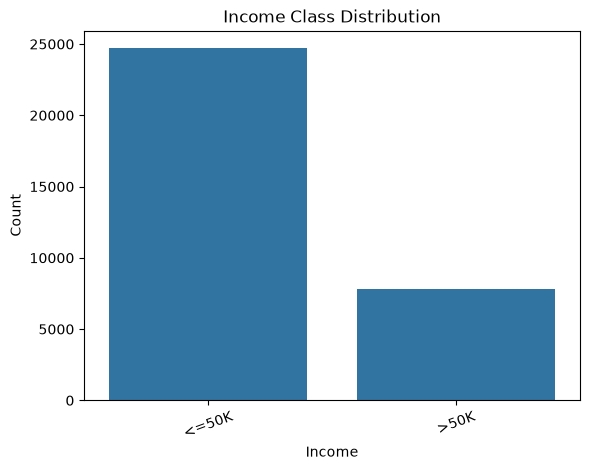

In [7]:
X = df.drop(columns=['income'])
y = df['income']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

sns.countplot(x=y)
plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (26029, 14)
Testing features: (6508, 14)
Training target: (26029,)
Testing target: (6508,)


In [9]:
numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=['number']
).columns.tolist()

# Decision Tree: numerical columns
numeric_dt = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# KNN: numerical columns with scaling
numeric_knn = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical columns
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_dt = ColumnTransformer(transformers=[
    ('num', numeric_dt, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

preprocessor_knn = ColumnTransformer(transformers=[
    ('num', numeric_knn, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)
print("Preprocessing pipelines created successfully")

Numerical columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Preprocessing pipelines created successfully


In [10]:
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor_dt),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=10,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree training completed")
print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10])

Decision Tree training completed

First 10 actual values:
<StringArray>
['<=50K',  '>50K', '<=50K', '<=50K', '<=50K', '<=50K', '<=50K', '<=50K',
 '<=50K',  '>50K']
Length: 10, dtype: str

First 10 predicted values:
['<=50K' '>50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K'
 '<=50K']


In [11]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(
    y_test, y_pred_dt, average='weighted', zero_division=0
)
dt_recall = recall_score(
    y_test, y_pred_dt, average='weighted', zero_division=0
)
dt_f1 = f1_score(
    y_test, y_pred_dt, average='weighted', zero_division=0
)

print("DECISION TREE RESULTS")
print("---------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_dt, zero_division=0
))

DECISION TREE RESULTS
---------------------
Accuracy : 0.8648
Precision: 0.8594
Recall   : 0.8648
F1-score : 0.8581

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4940
        >50K       0.79      0.60      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.84      0.77      0.80      6508
weighted avg       0.86      0.86      0.86      6508



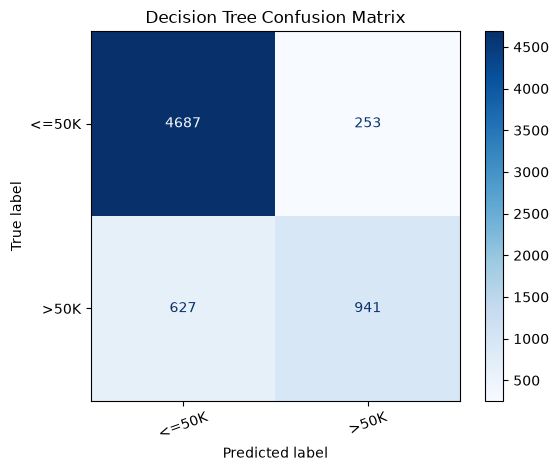

In [12]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=dt_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt_model.classes_
)

disp.plot(cmap='Blues', xticks_rotation=20)
plt.title("Decision Tree Confusion Matrix")
plt.show()

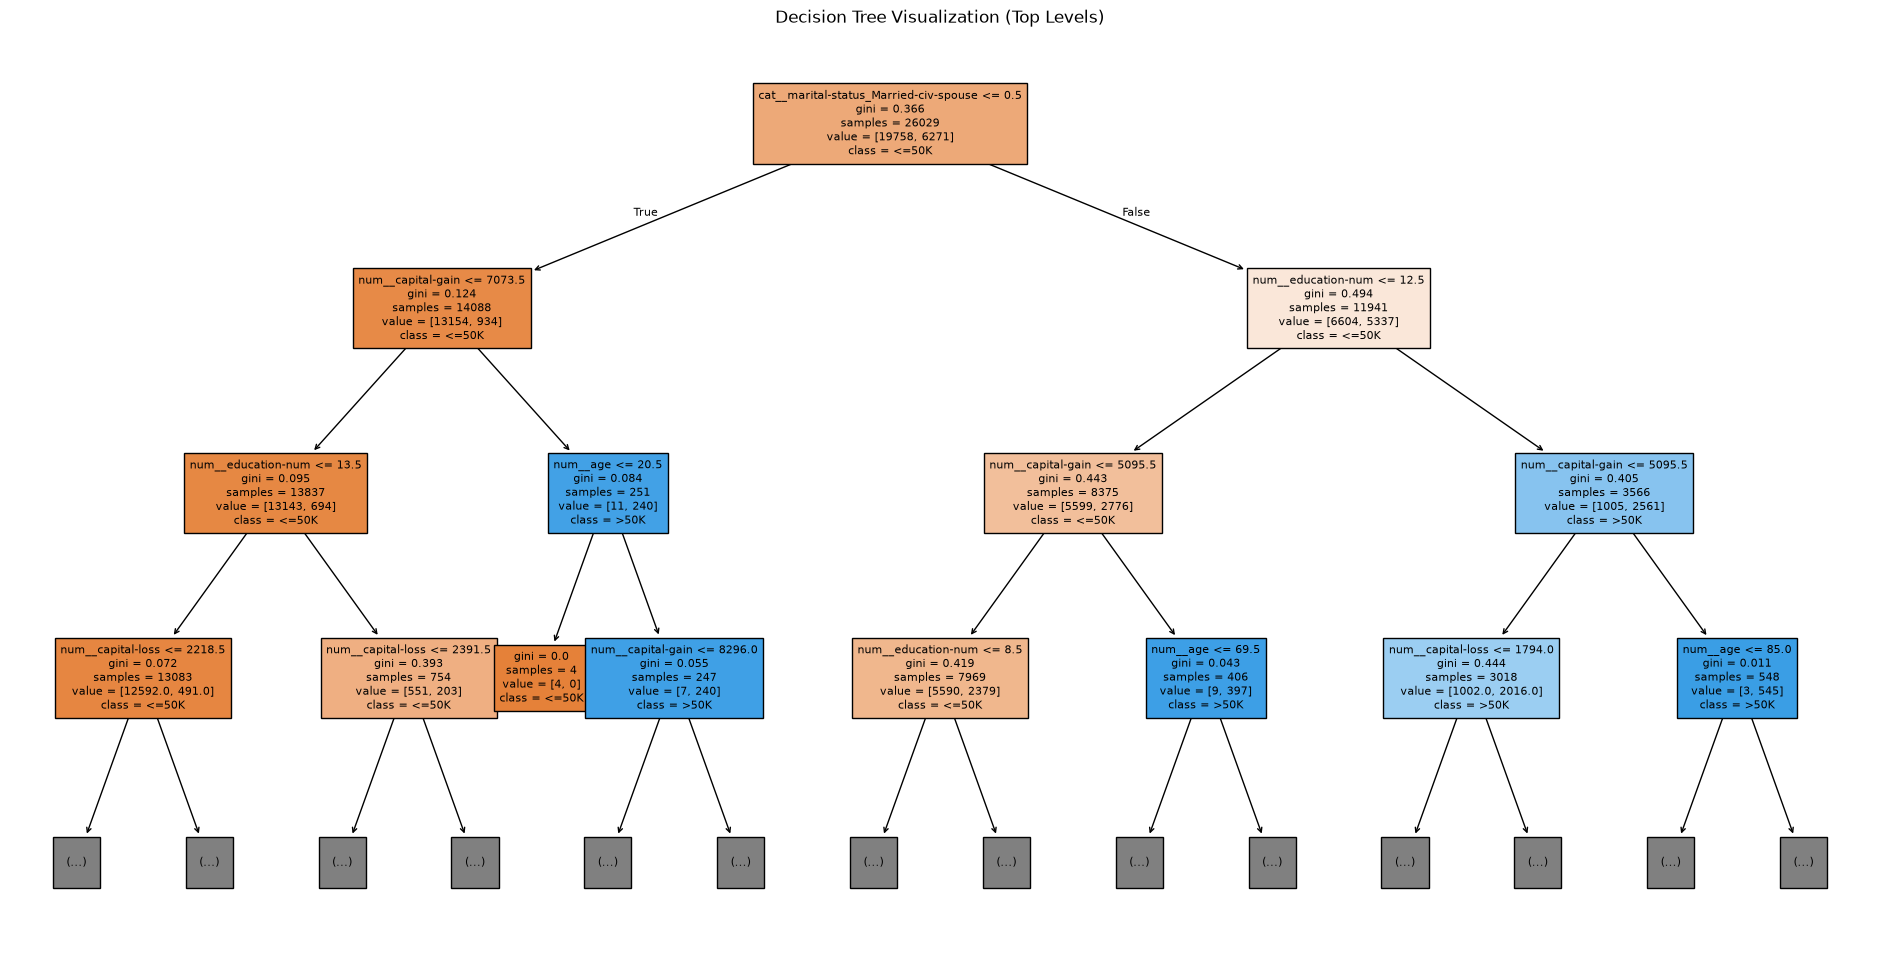

In [13]:
feature_names_dt = dt_model.named_steps[
    'preprocessor'
].get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model.named_steps['classifier'],
    feature_names=feature_names_dt,
    class_names=[str(c) for c in dt_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization (Top Levels)")
plt.show()

In [16]:
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='minkowski',
        p=2,
        n_jobs=-1
    ))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("KNN training completed")
print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_knn[:10])

KNN training completed

First 10 actual values:
<StringArray>
['<=50K',  '>50K', '<=50K', '<=50K', '<=50K', '<=50K', '<=50K', '<=50K',
 '<=50K',  '>50K']
Length: 10, dtype: str

First 10 predicted values:
['<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K' '<=50K'
 '<=50K']


In [17]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)
knn_recall = recall_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)
knn_f1 = f1_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)

print("KNN RESULTS")
print("-----------")
print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1-score : {knn_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_knn, zero_division=0
))

KNN RESULTS
-----------
Accuracy : 0.8379
Precision: 0.8339
Recall   : 0.8379
F1-score : 0.8355

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.89      4940
        >50K       0.68      0.62      0.65      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.76      0.77      6508
weighted avg       0.83      0.84      0.84      6508



ALGORITHM COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.8648,0.8594,0.8648,0.8581
1,KNN,0.8379,0.8339,0.8379,0.8355


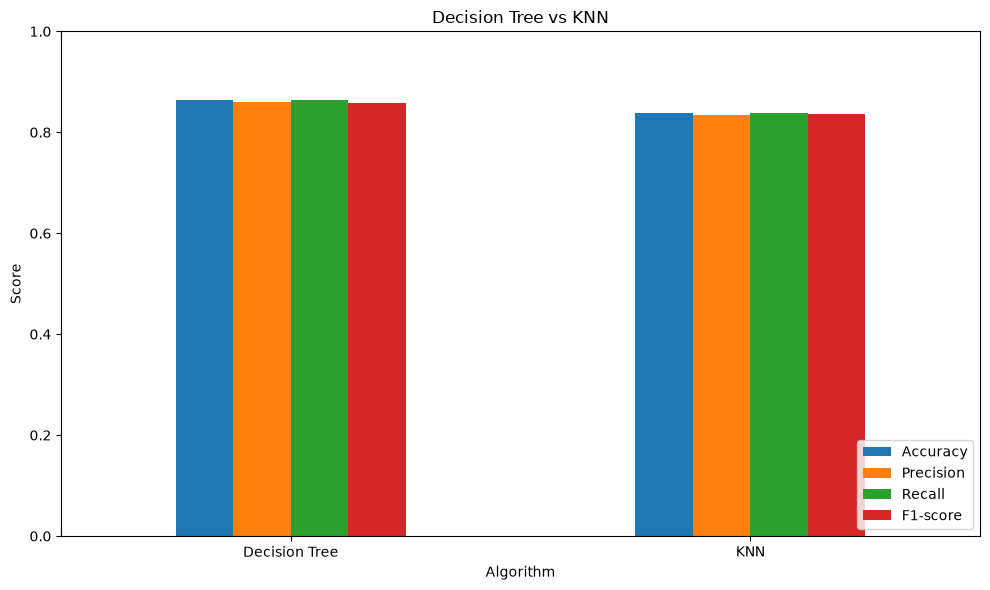

Higher accuracy in this test: Decision Tree


In [19]:
results = pd.DataFrame({
    'Algorithm': ['Decision Tree', 'KNN'],
    'Accuracy': [dt_accuracy, knn_accuracy],
    'Precision': [dt_precision, knn_precision],
    'Recall': [dt_recall, knn_recall],
    'F1-score': [dt_f1, knn_f1]
})

print("ALGORITHM COMPARISON")
display(results.round(4))

results.set_index('Algorithm').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Decision Tree vs KNN")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

best_model = results.loc[results['Accuracy'].idxmax(), 'Algorithm']
print("Higher accuracy in this test:", best_model)

In [20]:
sample_data = X_test.iloc[:5]

actual_values = y_test.iloc[:5]
dt_predictions = dt_model.predict(sample_data)
knn_predictions = knn_model.predict(sample_data)

prediction_results = pd.DataFrame({
    'Actual Income': actual_values.values,
    'Decision Tree Prediction': dt_predictions,
    'KNN Prediction': knn_predictions
})

display(prediction_results)

,Actual Income,Decision Tree Prediction,KNN Prediction
0,<=50K,<=50K,<=50K
1,>50K,>50K,<=50K
2,<=50K,<=50K,<=50K
3,<=50K,<=50K,<=50K
4,<=50K,<=50K,<=50K


In [22]:
from sklearn.model_selection import (
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

print("Additional libraries imported successfully")

Additional libraries imported successfully


In [24]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dt_cv_scores = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

knn_cv_scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

print("Decision Tree CV scores:", dt_cv_scores)
print("Decision Tree Mean CV Accuracy:", dt_cv_scores.mean())

print("\nKNN CV scores:", knn_cv_scores)
print("KNN Mean CV Accuracy:", knn_cv_scores.mean())

Decision Tree CV scores: [0.86016135 0.85497503 0.8484441  0.85074914 0.84860711]
Decision Tree Mean CV Accuracy: 0.8525873456438168

KNN CV scores: [0.83653477 0.82865924 0.84037649 0.82635421 0.82478386]
KNN Mean CV Accuracy: 0.8313417127876171


In [25]:
dt_param_grid = {
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 10],
    'classifier__criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_param_grid,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)

best_dt_model = dt_grid.best_estimator_

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("\nBest cross-validation accuracy:")
print(dt_grid.best_score_)

y_pred_dt_tuned = best_dt_model.predict(X_test)

print("\nTuned Decision Tree test accuracy:")
print(accuracy_score(y_test, y_pred_dt_tuned))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Decision Tree parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_split': 10}

Best cross-validation accuracy:
0.8501286785435226

Tuned Decision Tree test accuracy:
0.8646281499692686


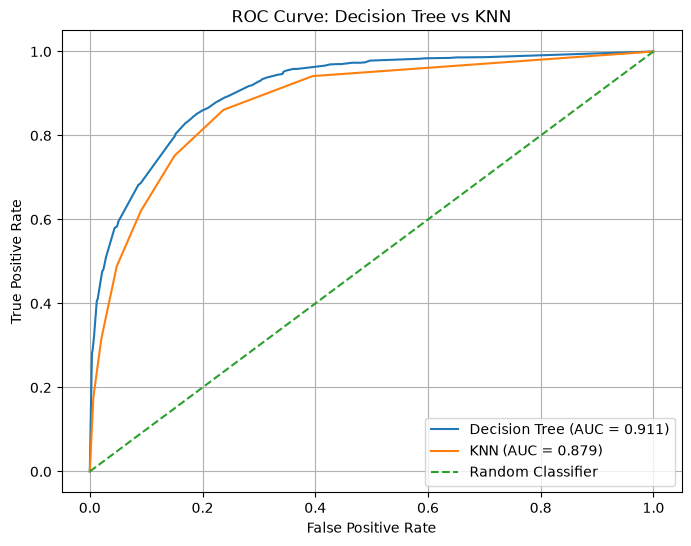

In [34]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

positive_class = '>50K'

y_test_binary = (y_test == positive_class).astype(int)

dt_positive_index = list(best_dt_model.classes_).index(positive_class)
knn_positive_index = list(best_knn_model.classes_).index(positive_class)

dt_prob = best_dt_model.predict_proba(X_test)[:, dt_positive_index]
knn_prob = best_knn_model.predict_proba(X_test)[:, knn_positive_index]

fpr_dt, tpr_dt, _ = roc_curve(y_test_binary, dt_prob)
fpr_knn, tpr_knn, _ = roc_curve(y_test_binary, knn_prob)

auc_dt = roc_auc_score(y_test_binary, dt_prob)
auc_knn = roc_auc_score(y_test_binary, knn_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.3f})')
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Decision Tree vs KNN')
plt.legend()
plt.grid(True)
plt.show()

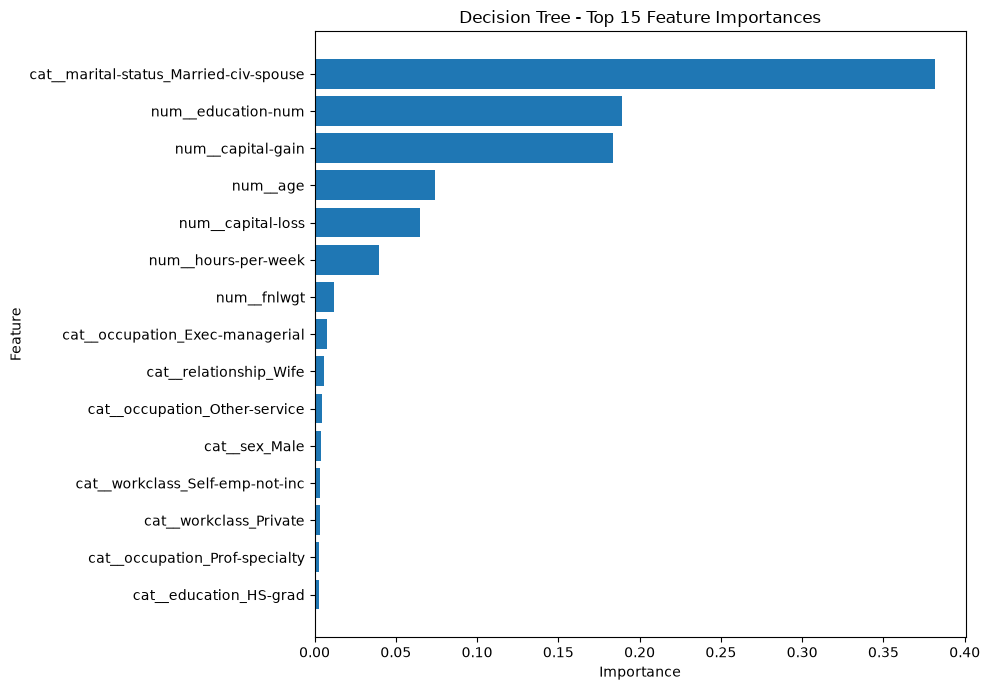

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

dt_classifier = best_dt_model.named_steps['classifier']
feature_names = best_dt_model.named_steps['preprocessor'].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_classifier.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 7))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Decision Tree - Top 15 Feature Importances')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

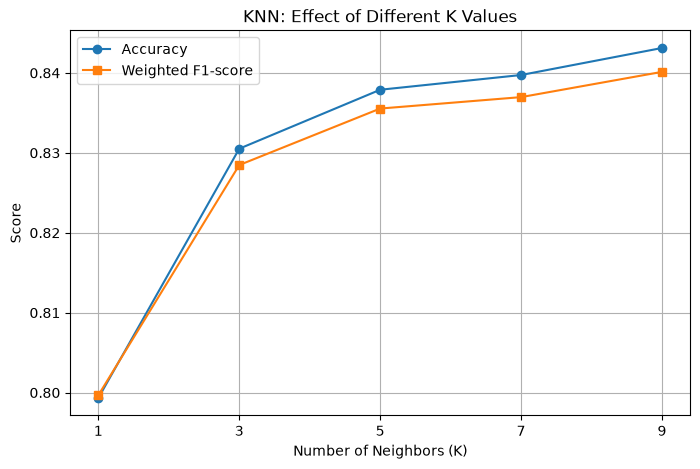

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_k_df['K'],
    knn_k_df['Accuracy'],
    marker='o',
    label='Accuracy'
)

plt.plot(
    knn_k_df['K'],
    knn_k_df['F1-score'],
    marker='s',
    label='Weighted F1-score'
)

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Score')
plt.title('KNN: Effect of Different K Values')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

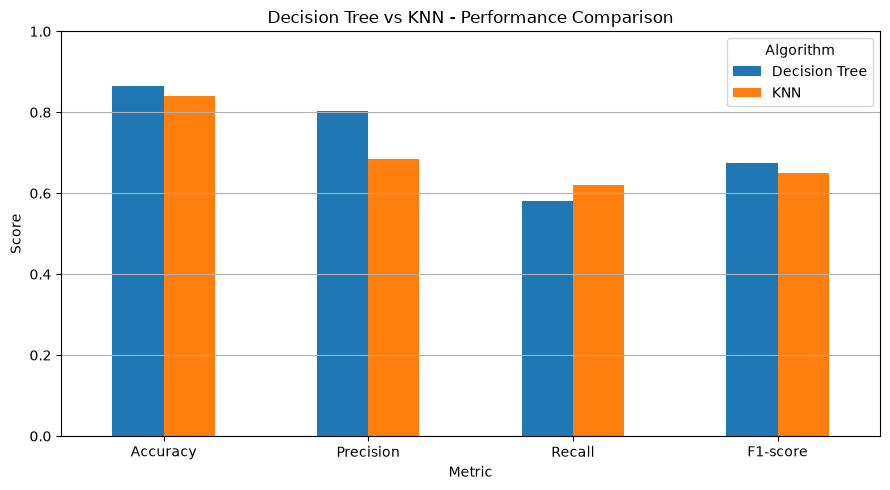

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

dt_pred = best_dt_model.predict(X_test)
knn_pred = best_knn_model.predict(X_test)

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Decision Tree': [
        accuracy_score(y_test, dt_pred),
        precision_score(y_test, dt_pred, pos_label='>50K', zero_division=0),
        recall_score(y_test, dt_pred, pos_label='>50K', zero_division=0),
        f1_score(y_test, dt_pred, pos_label='>50K', zero_division=0)
    ],
    'KNN': [
        accuracy_score(y_test, knn_pred),
        precision_score(y_test, knn_pred, pos_label='>50K', zero_division=0),
        recall_score(y_test, knn_pred, pos_label='>50K', zero_division=0),
        f1_score(y_test, knn_pred, pos_label='>50K', zero_division=0)
    ]
})

comparison.plot(x='Metric', kind='bar', figsize=(9, 5))
plt.title('Decision Tree vs KNN - Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Algorithm')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

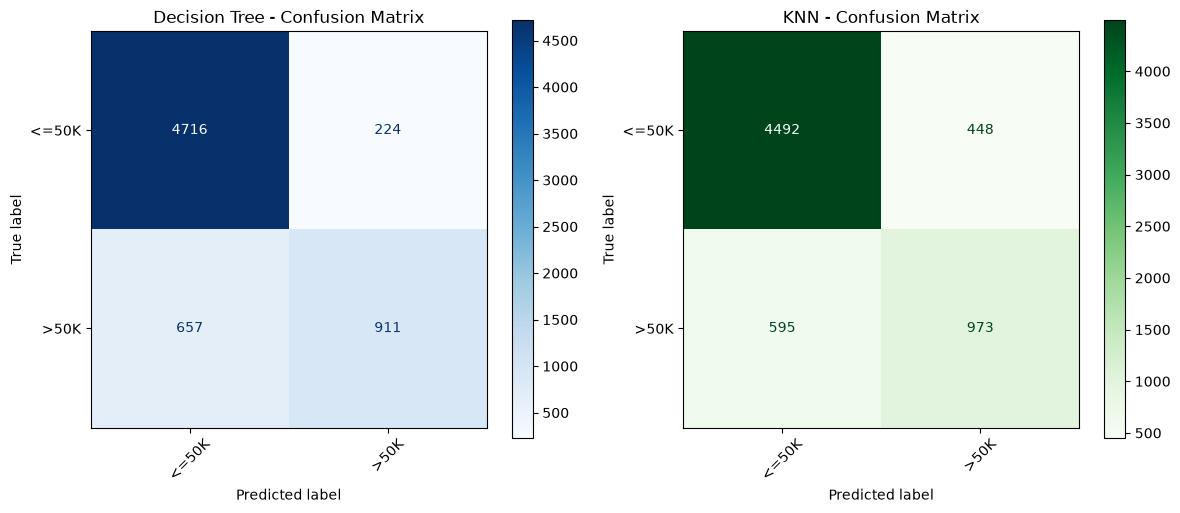

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

dt_pred = best_dt_model.predict(X_test)
knn_pred = best_knn_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred,
    ax=axes[0],
    cmap='Blues',
    xticks_rotation=45
)
axes[0].set_title('Decision Tree - Confusion Matrix')

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    ax=axes[1],
    cmap='Greens',
    xticks_rotation=45
)
axes[1].set_title('KNN - Confusion Matrix')

plt.tight_layout()
plt.show()